# Практика 8

In [ ]:
!pip install git+https://github.com/openai/CLIP.git

In [ ]:
from pathlib import Path
import gc
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Video, display
from PIL import Image
from tqdm.auto import tqdm

from video_lab import (COCO_CAPTION_IDS, BlipCaptioner, BlipQA, ClipEncoder, QwenQA,
                       coco_gallery, collage, letter_answer, load_rgb, read_clip,
                       sample_frames, windows)

DATA = Path("data")
if not (DATA / "questions.json").exists():
    raise FileNotFoundError("Откройте ноутбук из распакованной папки практики.")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RUN_BLIP = True
RUN_QWEN = DEVICE == "cuda"
if DEVICE == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
questions = json.loads((DATA / "questions.json").read_text(encoding="utf-8"))
saved_path = DATA / "model_examples.json"
saved_examples = json.loads(saved_path.read_text(encoding="utf-8")) if saved_path.exists() else {}
by_id = {row["id"]: row for row in questions}
video_paths = sorted(DATA.glob("*.mp4"))
print(f"{DEVICE=} · {RUN_BLIP=} · {RUN_QWEN=} · {len(video_paths)} клипов")


def get_clip(video_id):
    return read_clip(DATA / f"{video_id}.mp4")

## 1. Кадр, коллаж и последовательность

**Один кадр**

In [ ]:
display(Video(str(DATA / "key_then_coin.mp4"), embed=True, width=448))
intro_clip = get_clip("key_then_coin")
middle, times = sample_frames(intro_clip, 1)
print(f"Средний кадр: {times[0]:.2f} с")
display(middle[0])
display(intro_clip.frames[-1])

**Коллаж** упаковывает несколько моментов в одну картинку.

In [ ]:
for count, columns in [(4, 2), (16, 4)]:
    frames, times = sample_frames(intro_clip, count)
    print(f"{count} кадров")
    display(collage(frames, [f"{t:.2f} s" for t in times], columns=columns,
                    tile_size=(448 // columns, 280 // columns)))

**Последовательность** передаёт отдельные кадры по порядку. В видеорежиме Qwen-VL
также получает частоту выборки, чтобы различать длительность и темп.
Извлекаем кадры из центров равномерных интервалов.

In [ ]:
signal_clip = get_clip("signal")
display(Video(str(DATA / "signal.mp4"), embed=True, width=448))
for count in (4, 8, 16):
    frames, times = sample_frames(signal_clip, count)
    print(f"{count} кадров · {count / signal_clip.duration:.2f} FPS · секунды:", times)
    display(collage(frames, [f"{t:.2f}" for t in times], columns=4, tile_size=(112, 70)))

In [ ]:
video_array = np.stack([np.asarray(frame) for frame in frames])
print("Видеовход: форма (T, H, W, RGB)", video_array.shape)
print("Частота выбранных кадров:", len(video_array) / signal_clip.duration, "FPS")

## 2. CLIP

https://github.com/openai/CLIP

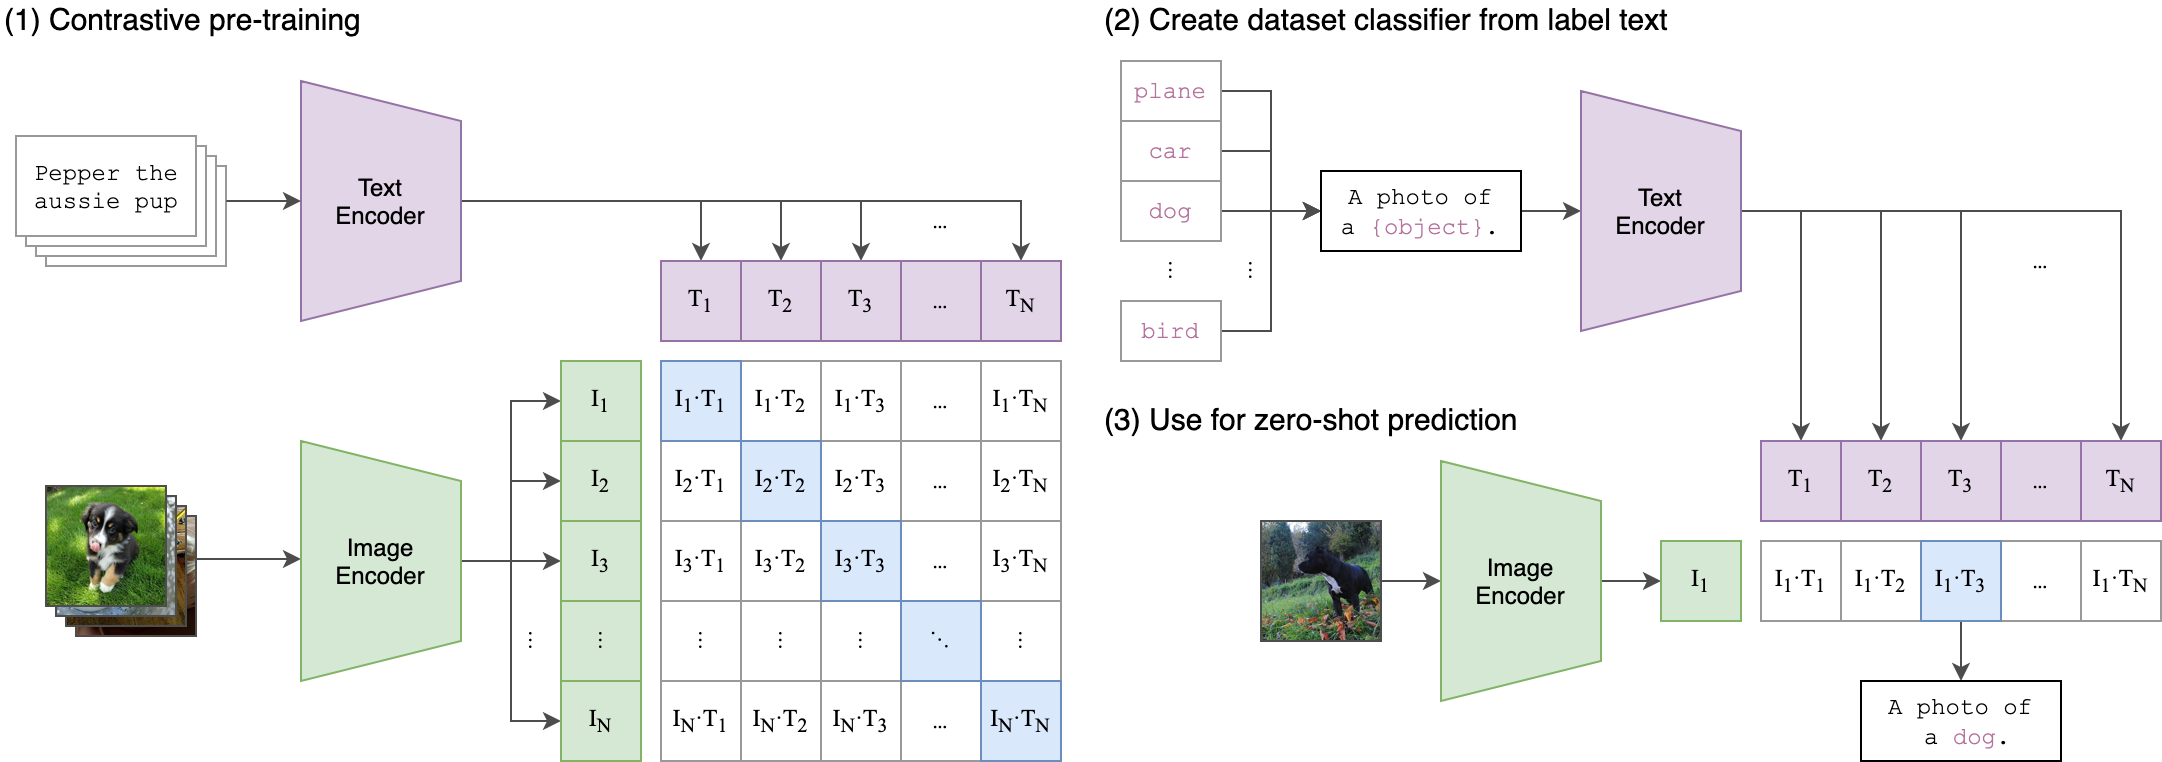

### COCO val2017

[COCO](https://cocodataset.org/#download)

In [ ]:
!wget -c https://s3.amazonaws.com/images.cocodataset.org/zips/val2017.zip -O /content/val2017.zip
!unzip -qn /content/val2017.zip -d /content

In [ ]:
COCO_DIR = Path("/content/val2017")
if not COCO_DIR.is_dir():
    COCO_DIR = Path("val2017")
COCO_INDEX_LIMIT = 128
coco_paths = coco_gallery(COCO_DIR)
print(f"COCO: {len(coco_paths)} фото в {COCO_DIR}")


def show_photos(images, titles, columns=5):
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 3 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(image)
        ax.set_title(title, fontsize=9, wrap=True)
    fig.tight_layout()
    plt.show()

### Модель и препроцессинг

Выведем список чекпойнтов, загрузим RN50 и посмотрим параметры входа. OpenAI CLIP
масштабирует изображение, обрезает его по центру, преобразует в RGB и нормализует
тензор.

In [ ]:
import clip

print(clip.available_models())
encoder = ClipEncoder(DEVICE, cache_dir=os.getenv("VIDEO_LAB_CLIP_CACHE"))
model, preprocess = encoder.model, encoder.preprocess
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Input resolution:", model.visual.input_resolution)
print("Context length:", model.context_length)
print("Vocab size:", model.vocab_size)
print(preprocess)
example = load_rgb(coco_paths[0]) if coco_paths else intro_clip.frames[-1]
image_tensor = preprocess(example)
print("Tensor shape:", tuple(image_tensor.shape))
normalization = preprocess.transforms[-1]
mean = torch.tensor(normalization.mean)[:, None, None]
std = torch.tensor(normalization.std)[:, None, None]
processed = (image_tensor * std + mean).clamp(0, 1).permute(1, 2, 0)
show_photos([example, processed], ["Исходное изображение", "После resize и center crop"], columns=2)

### Image search


In [ ]:
@torch.inference_mode()
def encode_text(text):
    tokens = clip.tokenize([text], truncate=True).to(DEVICE)
    features = model.encode_text(tokens).float()
    return torch.nn.functional.normalize(features).cpu().numpy()[0]


@torch.inference_mode()
def encode_image(image_path):
    image = preprocess(load_rgb(image_path)).unsqueeze(0).to(DEVICE)
    features = model.encode_image(image).float()
    return torch.nn.functional.normalize(features).cpu().numpy()[0]


rng = np.random.default_rng(42)
caption_names = {f"{image_id:012d}.jpg" for image_id in COCO_CAPTION_IDS}
caption_paths = [path for path in coco_paths if path.name in caption_names]
other_paths = [coco_paths[i] for i in rng.permutation(len(coco_paths))
               if coco_paths[i].name not in caption_names]
gallery_paths = (caption_paths + other_paths)[:COCO_INDEX_LIMIT]
gallery_batches = [
    encoder.images([load_rgb(path) for path in gallery_paths[start:start + 32]])
    for start in tqdm(range(0, len(gallery_paths), 32), desc="CLIP gallery")
]
gallery_vectors = np.concatenate(gallery_batches) if gallery_batches else None

In [ ]:
def show_neighbors(vector, exclude=None, k=5):
    scores = gallery_vectors @ vector
    best = [i for i in np.argsort(-scores, kind="stable") if gallery_paths[i] != exclude][:k]
    show_photos([load_rgb(gallery_paths[i]) for i in best],
                [f"{gallery_paths[i].stem} · {scores[i]:.2f}" for i in best])


if len(gallery_paths) >= 2:
    text_query = "a plate of food"
    text_vector = encode_text(text_query)
    print("Текстовый запрос:", text_query, "· размер эмбеддинга:", text_vector.shape)
    show_neighbors(text_vector)

    image_query = gallery_paths[int(rng.integers(len(gallery_paths)))]
    image_vector = encode_image(image_query)
    print("Запрос-картинка:", image_query.name, "· размер эмбеддинга:", image_vector.shape)
    display(load_rgb(image_query))
    show_neighbors(image_vector, exclude=image_query)
else:
    print("Для поиска по COCO нужны хотя бы две загруженные картинки.")

### Zero-shot classification

In [ ]:
categories = ["crowd", "animals", "food", "forest"]
prompts = ["a photo of a crowd", "a photo of animals", "a photo of food", "a photo of a forest"]
if gallery_paths:
    class_vectors = np.stack([encode_text(prompt) for prompt in prompts])
    count = min(25, len(gallery_paths))
    cosine = gallery_vectors[:count] @ class_vectors.T
    scale = model.logit_scale.detach().float().exp().item()
    probabilities = torch.softmax(torch.from_numpy(cosine * scale), dim=-1).numpy()
    classes = probabilities.argmax(axis=-1)
    show_photos([load_rgb(path) for path in gallery_paths[:count]],
                [f"{categories[i]} · {row[i]:.0%}" for row, i in zip(probabilities, classes)])

### От картинки к видео

Кадр видео можно обработать как обычное изображение. Возьмём кадр с велосипедистом
и ранжируем описания. Затем повторим поиск для нескольких моментов одного ролика.

**Задание 1.** Измените описание велосипедиста. Сравните ранги и сырые значения
сходства. Добавьте одно правдоподобное описание, которого на изображении нет.

In [ ]:
bike, _ = sample_frames(get_clip("bmx-trees"), 1)
display(bike[0])
descriptions = ["a cyclist riding a bicycle", "a person riding a horse",
                "a dog running in the grass"]
similarity = (encoder.images(bike) @ encoder.texts(descriptions).T)[0]
display(pd.DataFrame({"description": descriptions, "cosine": similarity})
        .sort_values("cosine", ascending=False))

**Задание 2.** Постройте график покадровых оценок. Сначала найдите кадры
по запросу про велосипедиста, затем попробуйте запрос про короткую красную вспышку
в клипе signal. Сравните положение пиков с кадрами и с одной оценкой CLIP для коллажа.

In [ ]:
def clip_timeline(video_id, query, count=12):
    frames, times = sample_frames(get_clip(video_id), count)
    scores = (encoder.images(frames) @ encoder.texts([query]).T).ravel()
    top = np.argsort(-scores, kind="stable")[:3]
    fig, ax = plt.subplots(figsize=(8, 2.6))
    ax.plot(times, scores, marker=".")
    ax.scatter(times[top], scores[top], color="tab:orange", label="top-3")
    ax.set(xlabel="Время, с", ylabel="Косинусное сходство", title=query)
    ax.legend()
    plt.show()
    display(collage([frames[i] for i in top], [f"{times[i]:.2f} s" for i in top], columns=3))
    four, _ = sample_frames(get_clip(video_id), 4)
    print("Сходство для коллажа 2×2:",
          round(float((encoder.images([collage(four)]) @ encoder.texts([query]).T)[0, 0]), 3))


clip_timeline("bmx-trees", "a person riding a bicycle")

In [ ]:
clip_timeline("signal", "a bright red indicator light", count=16)

## 3. BLIP

https://github.com/salesforce/BLIP

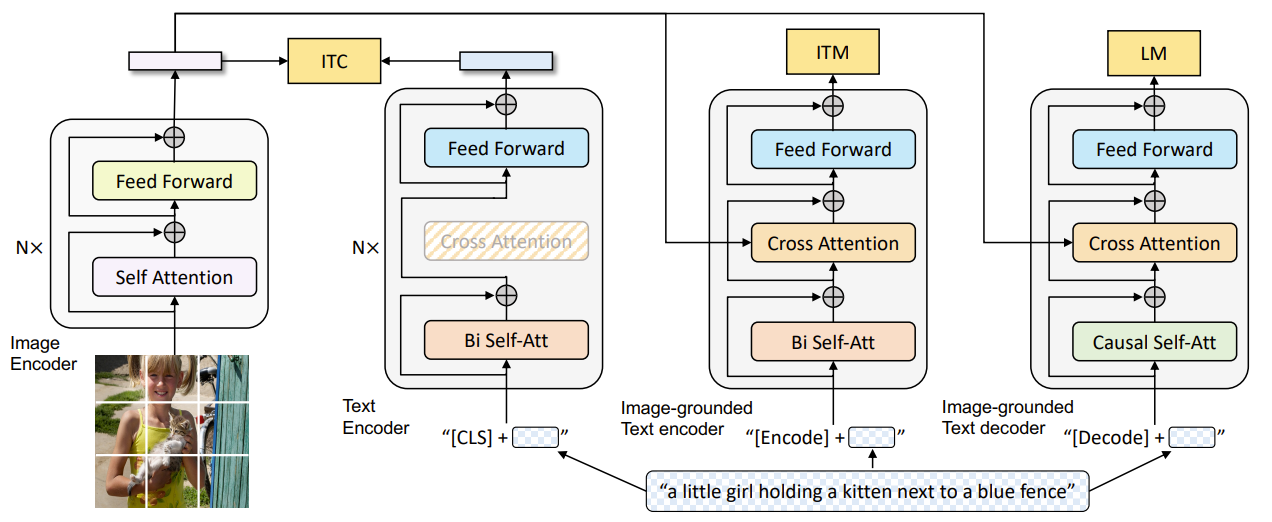
### Captioning на COCO

In [ ]:
coco_by_name = {path.name: path for path in coco_paths}
queries = [coco_by_name[f"{image_id:012d}.jpg"] for image_id in COCO_CAPTION_IDS
           if f"{image_id:012d}.jpg" in coco_by_name]
photos = [load_rgb(path) for path in queries]
if RUN_BLIP:
    blip = BlipCaptioner(DEVICE)
if photos:
    saved_captions = saved_examples.get("blip_coco_captions", {})
    captions = blip.captions(photos) if RUN_BLIP else [saved_captions.get(path.name) for path in queries]
    labeled = [(photo, f"{path.stem} · {caption}")
               for path, photo, caption in zip(queries, photos, captions) if caption]
    if labeled:
        if not RUN_BLIP:
            print("Сохранённые подписи BLIP:")
        show_photos([photo for photo, _ in labeled], [label for _, label in labeled], columns=2)

### Visual Question Answering на фото

https://huggingface.co/Salesforce/blip-vqa-base

In [ ]:
if photos:
    photo = photos[0]
    display(photo)
    visible_question = ("What animals are shown?" if queries[0].name == "000000473974.jpg"
                        else "What is the main object in the image?")
    photo_questions = [visible_question, "Which city is this photo taken in?"]
    if RUN_BLIP:
        blip_qa = BlipQA(DEVICE)
        photo_answers = {question: blip_qa.answer(photo, question) for question in photo_questions}
        del blip_qa
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    else:
        photo_answers = saved_examples.get("blip_coco_vqa", {}).get(queries[0].name, {})
    if photo_answers:
        if not RUN_BLIP:
            print("Сохранённые ответы BLIP:")
        display(pd.DataFrame(photo_answers.items(), columns=["question", "answer"]))

### От фото к кадрам и коллажам

**Задание 3.** Сравните подписи к отдельному кадру, коллажу и четырём кадрам по
отдельности.

In [ ]:
def inspect_captions(captioner, video_id, order=(0, 1, 2, 3)):
    frames, _ = sample_frames(get_clip(video_id), 4)
    sheet = collage([frames[i] for i in order])
    display(sheet)
    captions = captioner.captions([frames[2], sheet, *frames])
    labels = ["один кадр", "коллаж", "кадр 1", "кадр 2", "кадр 3", "кадр 4"]
    display(pd.DataFrame({"вход": labels, "подпись": captions}))


if RUN_BLIP:
    inspect_captions(blip, "bmx-trees")
else:
    print("Сохранённые подписи BLIP:")
    display(pd.DataFrame(saved_examples.get("blip", {})))

In [ ]:
if RUN_BLIP:
    inspect_captions(blip, "key_then_coin")
    inspect_captions(blip, "coin_then_key")
    inspect_captions(blip, "key_then_coin", order=(3, 2, 1, 0))

In [ ]:
if RUN_BLIP:
    del blip
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

## 4. Qwen2.5-VL

В видеорежиме
временные позиции учитывают частоту кадров. После обучения на инструкциях
модель генерирует ответы на вопросы по визуальному входу.

| Вход | Что получает Qwen | Для чего используем |
|---|---|---|
| Один кадр | Одно изображение и вопрос | Объекты, цвет, текст, простой базовый вариант |
| Коллаж | Одно изображение из нескольких плиток и инструкция о порядке чтения | Сравнение моментов, работа с ограниченным числом изображений |
| Видеовход | Упорядоченный список кадров, FPS выборки и вопрос | Порядок действий, движение, локализация |
| Несколько визуальных входов | Несколько изображений или клипов с идентификаторами | Сравнение фрагментов и выбор источника в RAG |

Формат выхода тоже зависит от инструкции. Открытый вопрос даёт текст, вопрос с
вариантами — короткую метку, а запрос на локализацию — интервал времени.
В таблице VideoQA просим одну букву и сохраняем сырой ответ для разбора ошибок.

**Задание 4.** Сравните один центральный кадр, коллаж и видеовход из тех же четырёх
кадров. В двух последних режимах исходная выборка одна и та же. Масштаб объектов,
компоновка и представление времени могут различаться. Буквы A/B/C и их порядок
фиксируем для каждого вопроса.

[Qwen2.5-VL-3B-Instruct](https://huggingface.co/Qwen/Qwen2.5-VL-3B-Instruct)

In [ ]:
def qa_prompt(row):
    options = "\n".join(f"{letter}. {label}" for letter, label in zip("ABC", row["options"]))
    return (
        "Use the visual input. If it is a 2 by 2 grid, read panels left to right "
        "and top to bottom. Reply with one letter: A, B, or C.\n"
        f"{row['question']}\n{options}"
    )


def qa_input(video_id, mode, count=4, reverse=False):
    clip = get_clip(video_id)
    frames, times = sample_frames(clip, 1 if mode == "single" else count)
    if reverse:
        frames = frames[::-1]
    if mode == "single":
        return [("", frames[0], None)], times
    if mode == "collage":
        return [("", collage(frames), None)], times
    if mode == "video":
        sampled_fps = count / clip.duration
        return [("", frames, sampled_fps)], times
    raise ValueError(mode)


def run_qa(rows, modes, count=4, reverse=False):
    results = []
    for row in rows:
        for mode in modes:
            media, times = qa_input(row["video"], mode, count, reverse)
            raw = qwen.answer(media, qa_prompt(row), max_new_tokens=8)
            answer = letter_answer(raw)
            results.append(dict(id=row["id"], kind=row["type"], mode=mode,
                                count=len(times), raw=raw, expected=row["answer"],
                                parsed=answer, correct=answer == row["answer"]))
    return pd.DataFrame(results)


print(qa_prompt(by_id["key_order"]))
display(qa_input("key_then_coin", "collage")[0][0][1])
if RUN_QWEN:
    qwen = QwenQA(DEVICE)
    qa_results = run_qa(questions, ["single", "collage", "video"])
elif "videoqa" in saved_examples:
    print("Сохранённый прогон Qwen-VL:")
    qa_results = pd.DataFrame(saved_examples["videoqa"])
if RUN_QWEN or "videoqa" in saved_examples:
    display(qa_results)
    display(qa_results.groupby(["kind", "mode"])["correct"].agg(["sum", "count", "mean"]))

In [ ]:
if RUN_QWEN:
    for question_id in ("key_order", "coin_order"):
        row = by_id[question_id]
        last = get_clip(row["video"]).frames[-1]
        print(question_id, qwen.answer([("", last, None)], qa_prompt(row), max_new_tokens=8))

In [ ]:
flash_row = by_id["flash"]
flash_results = []
for count in (4, 16):
    frames, times = sample_frames(get_clip("signal"), count)
    a, b = flash_row["evidence"]
    print(f"{count=} · кадры во время вспышки: {times[(a <= times) & (times < b)]}")
    if RUN_QWEN:
        result = run_qa([flash_row], ["video"], count=count)
        flash_results.extend(result.to_dict("records"))
        display(result)
if not RUN_QWEN and "flash" in saved_examples:
    display(pd.DataFrame(saved_examples["flash"]))

In [ ]:
if RUN_QWEN:
    reversed_cup = dict(by_id["cup_direction"], answer="A")
    display(run_qa([reversed_cup], ["collage", "video"], reverse=True))

In [ ]:
signal = get_clip("signal")
step = round(signal.fps / 4)
sampled = signal.frames[::step]
actual_sample_fps = signal.fps / step
print("Эталонный интервал, с:", flash_row["evidence"])
if RUN_QWEN:
    localization = qwen.answer([("", sampled, actual_sample_fps)],
                               "When is the indicator brightly illuminated? "
                               "Return the approximate start and end in seconds.")
    print(localization)
elif "localization" in saved_examples:
    print("Сохранённый ответ:", saved_examples["localization"])

## 5. Video RAG

**Цель.** Ответить на вопрос по архиву и показать фрагмент, где ответ можно проверить.
Например, по вопросу «На чём едет человек в лесу?» хотим получить «На велосипеде»
и название ролика с границами подходящего отрезка.

**RAG** (retrieval-augmented generation) добавляет к вопросу контекст из поиска.
В этой практике контекстом служат кадры из найденных окон видео.

| Этап | Что строим | Зачем |
|---|---|---|
| Индексация до запроса | Нарезаем видео на окна, выбираем кадры, усредняем и нормализуем CLIP-эмбеддинги. Сохраняем ID, имя видео и границы. | Поиск возвращает конкретный момент в архиве. Перекрытие помогает сохранить события на границах окон. |
| Поиск при запросе | Кодируем текст и берём три окна с наибольшим косинусным сходством. | Ограничиваем объём видео, которое анализирует Qwen. |
| Генерация | Передаём вопрос, найденные фрагменты и их ID. Qwen выбирает подтверждающий фрагмент или сообщает о недостатке данных. | Получаем ответ, который можно сверить с визуальным источником. |
| Ссылка на источник | Проверяем ID и берём границы окна из индекса. | Получаем таймкод по сохранённой разметке окна. |

В примере задаём поисковое описание и вопрос отдельно. CLIP ищет сцену по фразе
«a person riding a bicycle». Qwen получает вопрос «What is the person riding in
the forest?». Сходство с запросом помогает найти сцену, а проверка ответа
требует, чтобы нужная деталь попала в кадры.

По умолчанию каждый фрагмент передаём коллажом. Параметр as_video в функции
ответа позволяет передать те же кадры в видеорежиме. Таймкод в результате
обозначает границы окна.

Если подходящее окно не вошло в top-3, проверяем поиск. Если окно найдено, смотрим,
попало ли свидетельство в выбранные кадры и использовала ли его модель.

**Задание 7.** Соберите индекс с окном 4 секунды и шагом 2 секунды. Поиск выполняем
косинусным сходством.

In [ ]:
def build_index(paths, size=4, stride=2):
    items, vectors = [], []
    for path in paths:
        clip = read_clip(path)
        for start, end in windows(clip.duration, size, stride):
            frames, _ = sample_frames(clip, 4, start, end)
            vector = encoder.images(frames).mean(axis=0)
            vectors.append(vector / max(np.linalg.norm(vector), 1e-12))
            items.append({"id": f"W{len(items) + 1:02d}", "video": path.stem,
                          "start": start, "end": end, "frames": frames})
    return items, np.stack(vectors)


def retrieve(query, index, k=3):
    items, vectors = index
    scores = (vectors @ encoder.texts([query]).T).ravel()
    ranked = np.argsort(-scores, kind="stable")[:k]
    return [dict(items[i], score=float(scores[i])) for i in ranked]


def describe_hits(hits):
    return pd.DataFrame([{key: value for key, value in hit.items() if key != "frames"}
                         for hit in hits])


index = build_index(video_paths)
print(f"Окон в индексе: {len(index[0])}")

In [ ]:
def answer_from_hits(question, hits, as_video=False):
    media = []
    for hit in hits:
        frames = hit["frames"]
        fps = len(frames) / (hit["end"] - hit["start"])
        visual = frames if as_video else collage(frames)
        media.append((f"Evidence ID {hit['id']}", visual, fps if as_video else None))
    reading_order = ("Each evidence input is a short video. " if as_video else
                     "Each image is a four-frame grid, read left to right, top to bottom. ")
    raw = qwen.answer(
        media,
        reading_order + "Use only the visual evidence. If it is insufficient, reply exactly UNKNOWN. "
        "Otherwise reply on one line as ID | short answer, using one supplied ID. "
        f"Question: {question}",
    )
    if raw.strip().rstrip(".").upper() == "UNKNOWN":
        return {"status": "insufficient_evidence", "raw": raw}
    match = re.fullmatch(r"\s*(W\d+)\s*\|\s*(.+?)\s*", raw, flags=re.IGNORECASE)
    by_window = {hit["id"]: hit for hit in hits}
    if match is None or match[1].upper() not in by_window or not match[2].strip():
        return {"status": "invalid_model_output", "raw": raw}
    source = by_window[match[1].upper()]
    return {"status": "answered", "answer": match[2].strip(), "raw": raw,
            "video": source["video"], "start": source["start"], "end": source["end"]}


examples = [
    ("a person riding a bicycle", "What is the person riding in the forest?"),
    ("a person wearing a yellow backpack", "What is inside the yellow backpack?"),
]
rag_results = {}
for query, question in examples:
    hits = retrieve(query, index)
    print(question)
    display(describe_hits(hits))
    display(collage([collage(hit["frames"]) for hit in hits], [hit["id"] for hit in hits],
                    columns=3, tile_size=(224, 140)))
    if RUN_QWEN:
        rag_results[question] = answer_from_hits(question, hits)
        print(rag_results[question])
    elif question in saved_examples.get("rag", {}):
        print("Сохранённый ответ:", saved_examples["rag"][question])

In [ ]:
def evidence_coverage(start, end, expected_start, expected_end):
    intersection = max(0, min(end, expected_end) - max(start, expected_start))
    return intersection / (expected_end - expected_start)


evidence_start, evidence_end = by_id["bike_object"]["evidence"]
positive_hits = retrieve(examples[0][0], index)
hit_at_3 = any(
    hit["video"] == "bmx-trees"
    and evidence_coverage(hit["start"], hit["end"], evidence_start, evidence_end) >= 0.8
    for hit in positive_hits
)
print("Нужное окно в top-3:", hit_at_3)

## X-CLIP

X-CLIP добавляет обмен информацией между кадрами для сопоставления видео и текста.

[X-CLIP](https://github.com/microsoft/VideoX/tree/master/X-CLIP)

In [ ]:
gc.collect()

In [ ]:
RUN_XCLIP = True
if RUN_XCLIP:
    from transformers import XCLIPModel, XCLIPProcessor

    if RUN_QWEN and "qwen" in globals():
        del qwen
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    checkpoint = "microsoft/xclip-base-patch32"
    xprocessor = XCLIPProcessor.from_pretrained(checkpoint)
    xmodel = XCLIPModel.from_pretrained(checkpoint).to(DEVICE).eval()
    frames, _ = sample_frames(get_clip("bmx-trees"), xmodel.config.vision_config.num_frames)
    prompts = ["a person riding a bicycle", "a person wearing a yellow backpack"]
    text_vectors = encoder.texts(prompts)
    for order, sequence in [("обычный", frames), ("обратный", frames[::-1])]:
        baseline = (encoder.images(sequence) @ text_vectors.T).mean(axis=0)
        inputs = xprocessor.tokenizer(prompts, padding=True, return_tensors="pt")
        inputs.update(xprocessor.image_processor([sequence], return_tensors="pt"))
        inputs = inputs.to(DEVICE)
        with torch.inference_mode():
            scores = xmodel(**inputs).logits_per_video[0].float().cpu().numpy()
        display(pd.DataFrame({"порядок": order, "запрос": prompts,
                              "CLIP cosine": baseline, "X-CLIP logit": scores}))